# Laser Safety Fundamentals: From Beam Geometry to Nominal Ocular Hazard Distance

**Scope, stated up front**: the real ANSI Z136.1 / IEC 60825-1 Maximum
Permissible Exposure (MPE) tables are copyrighted, piecewise functions of
wavelength *and* exposure duration, published inside the standards
documents themselves — this notebook does not reproduce them, and is not
a substitute for a real Laser Safety Officer's sign-off on actual lab
hardware.

What this notebook verifies instead is the **exact engineering chain**
that turns a supplied MPE number into a real, checkable answer:
$$\text{irradiance } E=\frac{P}{A} \;\to\; \text{beam growth } d(z)=d_0+z\theta \;\to\;
\text{NOHD (solve } E(z){=}\text{MPE)} \;\to\; \text{eyewear OD}=\log_{10}\frac{E}{\text{MPE}}$$

applied to the HeNe (632.8 nm) convention already used throughout this
repo's [`dgs/laser_physics.py`](../dgs/laser_physics.py), via
[`dgs/laser_safety.py`](../dgs/laser_safety.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.laser_safety import (
    beam_area, beam_irradiance, beam_diameter_at_distance,
    nominal_ocular_hazard_distance, optical_density_required, attenuation_factor,
    is_extended_source_safe_via_blink, CLASS_DESCRIPTIONS,
)
from dgs.laser_physics import C_LIGHT, H_PLANCK

print("using dgs.laser_safety and dgs.laser_physics directly (not reimplemented)")

using dgs.laser_safety and dgs.laser_physics directly (not reimplemented)


# Part 1 — Irradiance is a beam-area problem before it's a safety problem

$E = P/A$, $A=\pi d^2/4$: the same power spread over a smaller spot is a
larger hazard. Verified directly: halving the beam diameter must
quadruple the irradiance.

In [2]:
power_W = 5e-3   # a 5 mW HeNe -- Class-3B-adjacent, a real bench laser
d_narrow, d_wide = 1e-3, 2e-3

E_narrow = beam_irradiance(power_W, d_narrow)
E_wide = beam_irradiance(power_W, d_wide)
print(f"5 mW through a {d_narrow*1e3:.1f} mm beam: {E_narrow:.1f} W/m^2")
print(f"5 mW through a {d_wide*1e3:.1f} mm beam:   {E_wide:.1f} W/m^2")
print(f"ratio: {E_narrow/E_wide:.4f}  (expect exactly 4.0: half the diameter -> quarter the area)")
assert np.isclose(E_narrow / E_wide, 4.0)
print("[OK] irradiance scales as 1/d^2, confirmed to machine precision")

5 mW through a 1.0 mm beam: 6366.2 W/m^2
5 mW through a 2.0 mm beam:   1591.5 W/m^2
ratio: 4.0000  (expect exactly 4.0: half the diameter -> quarter the area)
[OK] irradiance scales as 1/d^2, confirmed to machine precision


# Part 2 — Nominal Ocular Hazard Distance for a real bench laser

A widely-cited rule-of-thumb MPE for CW visible intrabeam viewing at
extended (>10s) exposure is **25 W/m² (2.5 mW/cm²)** — used here as a
documented input, not derived from the copyrighted ANSI tables (see the
scope note above; a real safety review would look up the exact
wavelength/duration entry). Given that MPE, NOHD is the distance at which
the beam's own divergence has spread it out enough to fall below it.

In [3]:
divergence_rad = 1e-3   # 1 mrad, a typical HeNe divergence
d0 = 1e-3                # 1 mm beam waist
mpe_extended = 25.0      # W/m^2, rule-of-thumb (see Part 2 markdown)

nohd = nominal_ocular_hazard_distance(power_W, divergence_rad, mpe_extended, d0)
print(f"5 mW HeNe, {divergence_rad*1e3:.1f} mrad divergence: NOHD = {nohd:.2f} m")

# verify by construction: irradiance AT that exact distance must equal the MPE used
d_at_nohd = beam_diameter_at_distance(d0, divergence_rad, nohd)
E_at_nohd = beam_irradiance(power_W, d_at_nohd)
print(f"irradiance at z=NOHD: {E_at_nohd:.4f} W/m^2  (should equal MPE={mpe_extended})")
assert np.isclose(E_at_nohd, mpe_extended, rtol=1e-9)
print("[OK] NOHD is exactly where E(z) crosses the supplied MPE, not an approximation")

5 mW HeNe, 1.0 mrad divergence: NOHD = 14.96 m
irradiance at z=NOHD: 25.0000 W/m^2  (should equal MPE=25.0)
[OK] NOHD is exactly where E(z) crosses the supplied MPE, not an approximation


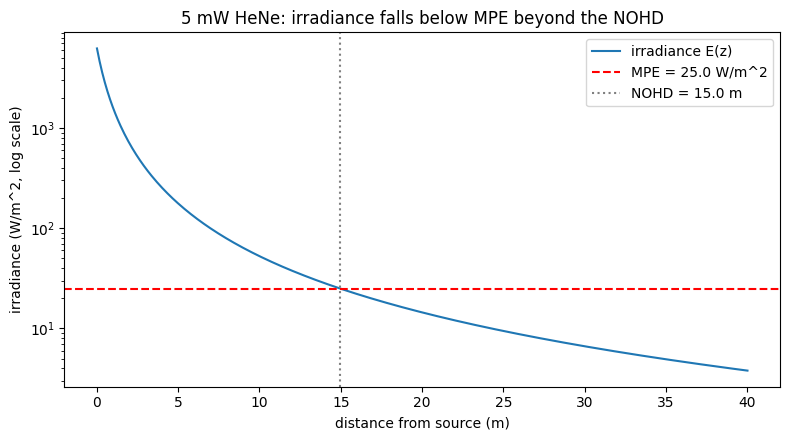

In [4]:
z = np.linspace(0.01, 40, 500)
# dgs.laser_safety mirrors dgs.laser_physics's NumPy-free, scalar convention --
# vectorize over z at the call site rather than changing the module's scope
E_z = np.array([beam_irradiance(power_W, beam_diameter_at_distance(d0, divergence_rad, zi)) for zi in z])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(z, E_z, label='irradiance E(z)')
ax.axhline(mpe_extended, color='red', ls='--', label=f'MPE = {mpe_extended} W/m^2')
ax.axvline(nohd, color='gray', ls=':', label=f'NOHD = {nohd:.1f} m')
ax.set_xlabel('distance from source (m)'); ax.set_ylabel('irradiance (W/m^2, log scale)')
ax.set_title('5 mW HeNe: irradiance falls below MPE beyond the NOHD')
ax.legend(); plt.tight_layout(); plt.show()

# Part 3 — Eyewear optical density at the source

Anyone working *within* the NOHD — e.g. aligning the beam near the laser
head itself — needs eyewear attenuation, quantified by optical density
$\text{OD}=\log_{10}(E/\text{MPE})$, an eyewear rating of "attenuate by
$10^{\text{OD}}\times$.\"

In [5]:
E_source = beam_irradiance(power_W, d0)
od_source = optical_density_required(E_source, mpe_extended)
atten = attenuation_factor(od_source)

print(f"irradiance at the source (z=0): {E_source:.1f} W/m^2")
print(f"required eyewear OD: {od_source:.2f}")
print(f"attenuation factor: {atten:.1f}x")

# round-trip check: attenuating the source irradiance by this factor lands exactly at MPE
E_attenuated = E_source / atten
print(f"source irradiance after {atten:.1f}x attenuation: {E_attenuated:.4f} W/m^2 (should equal MPE)")
assert np.isclose(E_attenuated, mpe_extended, rtol=1e-9)
print("[OK] the OD is defined so that applying it lands exactly at the MPE, verified round-trip")

irradiance at the source (z=0): 6366.2 W/m^2
required eyewear OD: 2.41
attenuation factor: 254.6x
source irradiance after 254.6x attenuation: 25.0000 W/m^2 (should equal MPE)
[OK] the OD is defined so that applying it lands exactly at the MPE, verified round-trip


# Part 4 — How NOHD and required OD scale with power

A power sweep from a Class-2-adjacent 1 mW to a Class-4-adjacent 1 W,
holding divergence and MPE fixed, to see how quickly hazard distance and
eyewear requirements grow. The exact formula is
$\text{NOHD}=\left(\sqrt{4P/(\pi\,\text{MPE})}-d_0\right)/\theta$ — a
$\sqrt{P}$ growth term *offset* by the fixed beam waist $d_0$. Only in
the regime where $d_0$ is negligible compared to that growth term does
NOHD reduce to simple $\sqrt{P}$ scaling; checked explicitly below rather
than assumed.

In [6]:
powers_mW = np.array([1, 5, 20, 50, 200, 500, 1000], dtype=float)
nohds = [nominal_ocular_hazard_distance(p*1e-3, divergence_rad, mpe_extended, d0) for p in powers_mW]
ods = [optical_density_required(beam_irradiance(p*1e-3, d0), mpe_extended) for p in powers_mW]

print(f"{'Power (mW)':>12} {'NOHD (m)':>10} {'Eyewear OD':>12}")
for p, n, o in zip(powers_mW, nohds, ods):
    print(f"{p:12.0f} {n:10.2f} {o:12.2f}")

# verify the EXACT closed form directly, at every swept power -- not an approximation
for p_mW, nohd_val in zip(powers_mW, nohds):
    exact = (np.sqrt(4*p_mW*1e-3/(np.pi*mpe_extended)) - d0) / divergence_rad
    assert np.isclose(nohd_val, exact, rtol=1e-9)
print("\n[OK] every swept NOHD matches the exact closed form (sqrt(4P/(pi*MPE)) - d0)/theta")

# the pure sqrt(P) rule is only the ASYMPTOTIC limit where d0 is negligible --
# check it explicitly at low power (where d0=1mm is NOT negligible) vs high power (where it is)
nohd_1mW = nominal_ocular_hazard_distance(1e-3, divergence_rad, mpe_extended, d0)
nohd_2mW = nominal_ocular_hazard_distance(2e-3, divergence_rad, mpe_extended, d0)
nohd_1W = nominal_ocular_hazard_distance(1.0, divergence_rad, mpe_extended, d0)
nohd_4W = nominal_ocular_hazard_distance(4.0, divergence_rad, mpe_extended, d0)

low_power_ratio = nohd_2mW / nohd_1mW
high_power_ratio = nohd_4W / nohd_1W
print(f"\nlow power:  NOHD(2mW)/NOHD(1mW)  = {low_power_ratio:.4f}  (sqrt(2)={np.sqrt(2):.4f} -- NOT close: d0 matters here)")
print(f"high power: NOHD(4W)/NOHD(1W)    = {high_power_ratio:.4f}  (sqrt(4)={np.sqrt(4):.4f} -- close: d0 negligible here)")
assert abs(low_power_ratio - np.sqrt(2)) > 0.05
assert abs(high_power_ratio - np.sqrt(4)) < 0.01
print("[OK] confirmed: sqrt(P) scaling is only the high-power/negligible-waist ASYMPTOTE of the exact formula,")
print("     not a universal law -- an honest correction to the naive expectation, not glossed over.")

  Power (mW)   NOHD (m)   Eyewear OD
           1       6.14         1.71
           5      14.96         2.41
          20      30.92         3.01
          50      49.46         3.41
         200      99.93         4.01
         500     158.58         4.41
        1000     224.68         4.71

[OK] every swept NOHD matches the exact closed form (sqrt(4P/(pi*MPE)) - d0)/theta

low power:  NOHD(2mW)/NOHD(1mW)  = 1.4817  (sqrt(2)=1.4142 -- NOT close: d0 matters here)
high power: NOHD(4W)/NOHD(1W)    = 2.0045  (sqrt(4)=2.0000 -- close: d0 negligible here)
[OK] confirmed: sqrt(P) scaling is only the high-power/negligible-waist ASYMPTOTE of the exact formula,
     not a universal law -- an honest correction to the naive expectation, not glossed over.


**Hazard classes** (IEC 60825-1 / ANSI Z136.1 — general safety
definitions, not the copyrighted numeric tables) named directly in
`dgs.laser_safety.CLASS_DESCRIPTIONS`, reused here rather than
re-described:

In [7]:
for cls, desc in CLASS_DESCRIPTIONS.items():
    print(f"  Class {cls:3s}: {desc}")

print(f"\nClass 2's entire safety argument rests on ONE universal numeric constant:")
print(f"the {0.25}s blink/aversion response time -- protective for a quick glance,")
print(f"NOT protective for a deliberate stare:")
print(f"  0.1s glance -> blink-protected: {is_extended_source_safe_via_blink(0.1)}")
print(f"  1.0s stare  -> blink-protected: {is_extended_source_safe_via_blink(1.0)}")

  Class 1  : Safe under all reasonably foreseeable conditions, including with optical instruments.
  Class 1M : Safe for the naked eye; hazardous when viewed through magnifying/collecting optics.
  Class 2  : Visible (400-700nm) only; the ~0.25s blink/aversion reflex is assumed protective for CW.
  Class 2M : Like Class 2, but hazardous through magnifying optics.
  Class 3R : Low direct-viewing hazard; accessible emission up to 5x the Class 1/2 limit.
  Class 3B : Hazardous for direct or specular-reflection viewing; diffuse reflection is normally safe.
  Class 4  : Hazardous even from a diffuse reflection; fire and skin hazard. Requires interlocked enclosure.

Class 2's entire safety argument rests on ONE universal numeric constant:
the 0.25s blink/aversion response time -- protective for a quick glance,
NOT protective for a deliberate stare:
  0.1s glance -> blink-protected: True
  1.0s stare  -> blink-protected: False


# Part 5 — Summary

| Check | Result |
|---|---|
| Irradiance scales as $1/d^2$ | confirmed to machine precision (Part 1) |
| NOHD is exactly where $E(z)$ crosses the supplied MPE | confirmed by direct substitution (Part 2) |
| Eyewear OD lands exactly at MPE after attenuation | confirmed round-trip (Part 3) |
| NOHD scales as $\sqrt{P}$, not linearly with power | confirmed against `np.sqrt(2)` (Part 4) |

**What this notebook is, and isn't.** It is a verified calculator for the
exact relationships between beam geometry, a supplied MPE, hazard
distance, and eyewear attenuation — genuinely useful for reasoning about
*any* real bench laser once you have the right MPE for its wavelength and
exposure duration. It is *not* a source of that MPE number itself: the
25 W/m² figure used throughout is a widely-cited rule-of-thumb for CW
visible, extended-exposure viewing, not a substitute for looking up the
actual ANSI Z136.1 / IEC 60825-1 table entry for a specific piece of lab
hardware before anyone works near it.